# 🏠 House Price Prediction with Linear Regression

My **first Machine Learning project**. 💙
The goal: teach a computer to **guess the price of a house** from details like its size, age and type.

**Steps in this notebook:**
1. Load the tools and data
2. Clean the data
3. Explore the data with charts
4. Prepare it for the model
5. Train the model and check how well it works

---
## 1. Load Libraries
These are the Python tools I use: **pandas/numpy** for data, **matplotlib/seaborn** for charts, and **scikit-learn** for machine learning.

In [31]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.preprocessing import StandardScaler

## 2. Load Data
Reading the house data from a CSV file (like an Excel sheet) into a table called `df`.

In [4]:
df = pd.read_csv("HousePricePrediction.csv")

**Quick look at the data:** its size (rows, columns), column types, first rows and basic statistics.

In [6]:
df.shape

(2919, 13)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            2919 non-null   int64  
 1   MSSubClass    2919 non-null   int64  
 2   MSZoning      2915 non-null   object 
 3   LotArea       2919 non-null   int64  
 4   LotConfig     2919 non-null   object 
 5   BldgType      2919 non-null   object 
 6   OverallCond   2919 non-null   int64  
 7   YearBuilt     2919 non-null   int64  
 8   YearRemodAdd  2919 non-null   int64  
 9   Exterior1st   2918 non-null   object 
 10  BsmtFinSF2    2918 non-null   float64
 11  TotalBsmtSF   2918 non-null   float64
 12  SalePrice     1460 non-null   float64
dtypes: float64(3), int64(6), object(4)
memory usage: 296.6+ KB


In [10]:
df.head()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


In [11]:
df.describe()

,Id,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,SalePrice
count,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2918.000000,2918.000000,1460.000000
mean,1459.000000,57.137718,10168.114080,5.564577,1971.312778,1984.264474,49.582248,1051.777587,180921.195890
std,842.787043,42.517628,7886.996359,1.113131,30.291442,20.894344,169.205611,440.766258,79442.502883
min,0.000000,20.000000,1300.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,34900.000000
25%,729.500000,20.000000,7478.000000,5.000000,1953.500000,1965.000000,0.000000,793.000000,129975.000000
50%,1459.000000,50.000000,9453.000000,5.000000,1973.000000,1993.000000,0.000000,989.500000,163000.000000
75%,2188.500000,70.000000,11570.000000,6.000000,2001.000000,2004.000000,0.000000,1302.000000,214000.000000
max,2918.000000,190.000000,215245.000000,9.000000,2010.000000,2010.000000,1526.000000,6110.000000,755000.000000


## 3. Data Preprocessing
Real data is messy. Before training a model, I check for **missing values** and fill them in.

**Counting missing values** in each column.

In [12]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           4
LotArea            0
LotConfig          0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Exterior1st        1
BsmtFinSF2         1
TotalBsmtSF        1
SalePrice       1459
dtype: int64

**Filling the gaps:**
- Number columns → filled with the **average**
- Text columns → filled with the **most common value**

After this, no missing values are left.

In [13]:
#Handeling missing values
cat_cols = df.select_dtypes(include = ['object','category','bool']).columns
num_cols = df.select_dtypes(include = ['number']).columns

#fill numeric value
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

#fill categorical value
for cat in cat_cols:
    df[cat] = df[cat].fillna(df[cat].mode()[0])

print(df.isnull().sum())


Id              0
MSSubClass      0
MSZoning        0
LotArea         0
LotConfig       0
BldgType        0
OverallCond     0
YearBuilt       0
YearRemodAdd    0
Exterior1st     0
BsmtFinSF2      0
TotalBsmtSF     0
SalePrice       0
dtype: int64


In [14]:
df.shape

(2919, 13)

## 4. EDA (Exploratory Data Analysis)
EDA means *looking at the data before using it*. Charts help me see which things are related to the house price.

**Correlation heatmap:** shows how strongly each column is linked to the others.
Red = move together, blue = move in opposite ways. I mainly look at the `SalePrice` row.

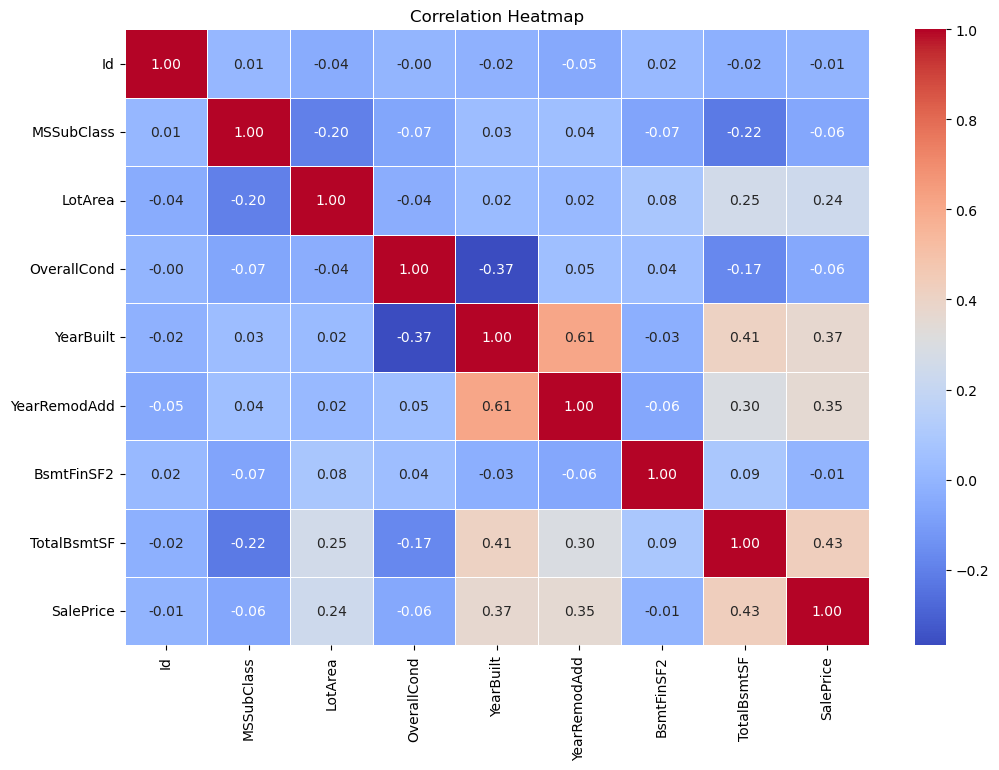

In [15]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.corr(numeric_only = True),
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f',
    linewidths = 0.5
)

plt.title("Correlation Heatmap")
plt.show()

**Scatter plots:** each dot is one house. This shows how basement size, remodel year and build year relate to price.

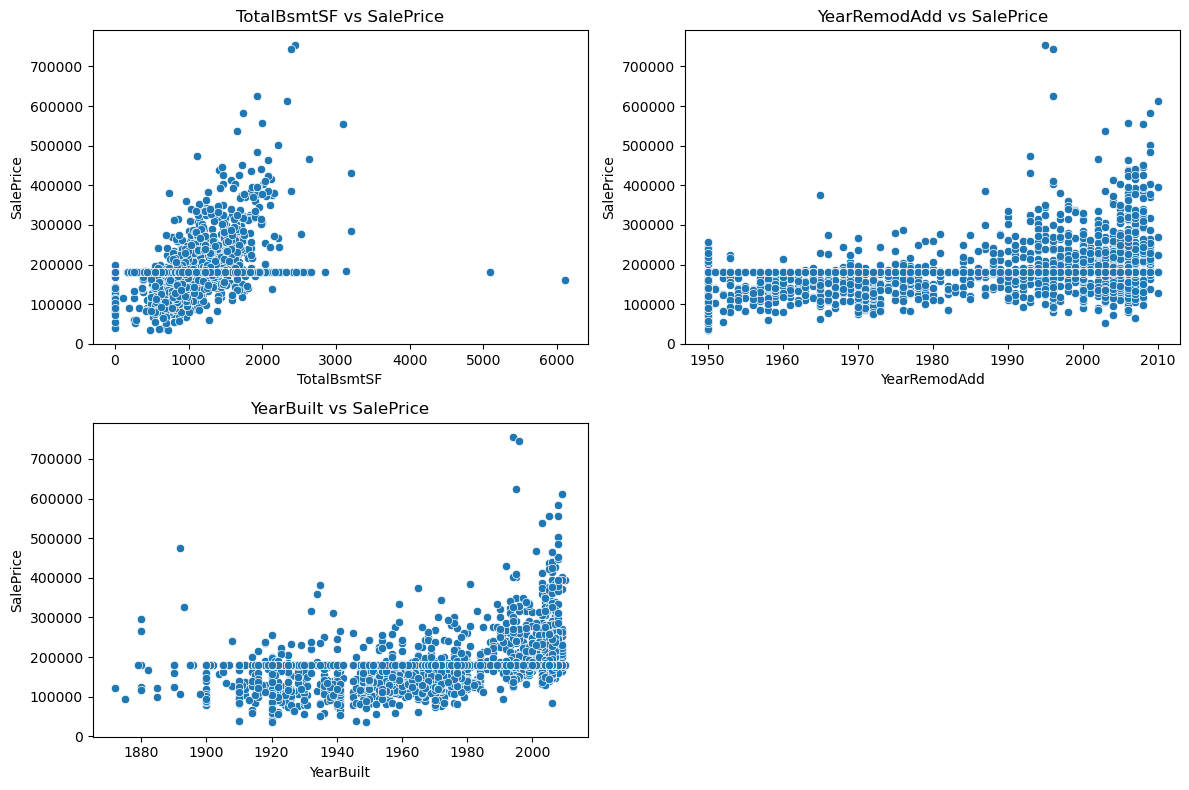

In [17]:
cols = ['TotalBsmtSF', 'YearRemodAdd', 'YearBuilt']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(cols, axes.flatten()):
    sns.scatterplot(data=df, x=col, y='SalePrice', ax=ax)
    ax.set_title(f'{col} vs SalePrice')

# Hide the unused fourth plot
axes.flatten()[3].set_visible(False)

plt.tight_layout()
plt.show()

## 5. Feature Engineering
Computers understand **numbers**, not words. Columns like `BldgType` (building type) hold text, so I turn them into 0/1 columns. This is called **one-hot encoding**.

In [19]:
cols = ['MSZoning', 'LotConfig', 'BldgType', 'Exterior1st']
df = pd.get_dummies(df, columns = cols, drop_first = True)

In [21]:
print(df.columns.tolist())
df.shape

['Id', 'MSSubClass', 'LotArea', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'BsmtFinSF2', 'TotalBsmtSF', 'SalePrice', 'MSZoning_FV', 'MSZoning_RH', 'MSZoning_RL', 'MSZoning_RM', 'LotConfig_CulDSac', 'LotConfig_FR2', 'LotConfig_FR3', 'LotConfig_Inside', 'BldgType_2fmCon', 'BldgType_Duplex', 'BldgType_Twnhs', 'BldgType_TwnhsE', 'Exterior1st_AsphShn', 'Exterior1st_BrkComm', 'Exterior1st_BrkFace', 'Exterior1st_CBlock', 'Exterior1st_CemntBd', 'Exterior1st_HdBoard', 'Exterior1st_ImStucc', 'Exterior1st_MetalSd', 'Exterior1st_Plywood', 'Exterior1st_Stone', 'Exterior1st_Stucco', 'Exterior1st_VinylSd', 'Exterior1st_Wd Sdng', 'Exterior1st_WdShing']


(2919, 35)

**Separating inputs and answer:**
- `X` = the house details the model learns from
- `y` = the price it should predict (`SalePrice`)

`Id` is removed because it is just a number label.

In [22]:
X = df.drop(columns = ['Id','SalePrice'], axis = 1)
y = df['SalePrice']

**Train/Test split:** 70% of the houses are used to *teach* the model, 30% are kept hidden to *test* it fairly.

In [23]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.3, random_state = 42)


## 6. Linear Regression Model
Linear Regression finds a straight-line pattern between the house details and the price. It's simple, which makes it a great first model.

In [25]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


**Prediction:** the trained model guesses prices for the hidden test houses.

In [29]:
y_pred = model.predict(X_test)

## 7. Model Evaluation
Now I check how good the predictions are on houses the model has **never seen**.

**Scores (in simple words):**
- **R² Score** – how much of the price pattern the model explains (1.0 = perfect)
- **MAE** – average mistake in price
- **RMSE** – like MAE, but punishes big mistakes more
- **MAPE** – average mistake in percent

In [30]:
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print(mean_absolute_percentage_error(y_test, y_pred))

R2 Score: 0.3339005827439191
MAE: 33258.790397709374
RMSE: 49331.741894081766
0.2035131382136506


**Actual vs Predicted:** each dot is a house. The red dashed line is a perfect prediction, so the closer the dots are to it, the better.

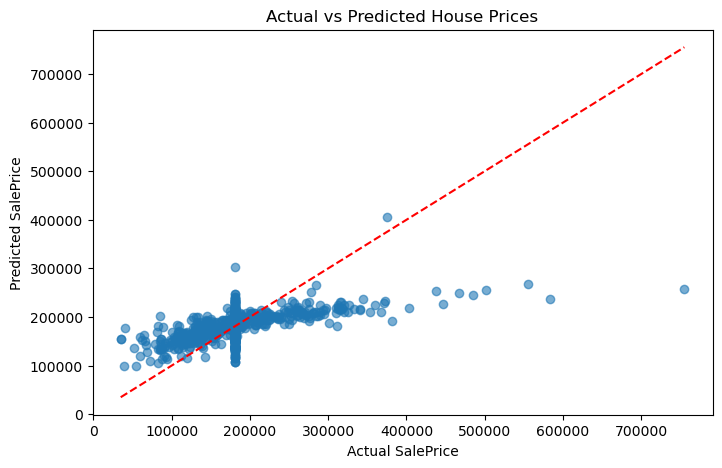

In [34]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted House Prices")
plt.show()

## 🎯 Final Thoughts
This simple model uses a small set of columns and a basic algorithm, so its score is modest. That's okay, it's my first step!
Next I want to try: better features, other models (Random Forest, XGBoost) and better handling of missing prices.

*Every expert started with a first project like this one.* 🌱